In [1]:
import cuml

from cuml.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

import sklearn

import matplotlib.pyplot as plt

import xgboost as xgb
import lightgbm as lgb

import torch

import numpy as np
import cupy as cp

import pandas as pd
from pathlib import Path
import gc

In [2]:
# RF

RF = {
    "model": RandomForestRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [20, 21, 1],
    "n_bins": [128, 256, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

In [3]:
# ET

ET = {
    "model": ExtraTreesRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [21, 21, 1],
    "min_samples_leaf": [4, 4, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

In [4]:
datasetPath = Path("/home/philipm/Desktop/ML-For-CV-Robustness/datasets/illumShift/datasetTreesIllumShift-shadowClas.csv")

#making sure
datasetPath.is_file()

True

In [5]:
dataset = pd.read_csv(datasetPath)
dataset.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,shadowInd,grviOut
0,0.224674,0.000277,0.000397,1141.969,1031.228,0.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0,0.088270
1,0.196116,0.000391,0.000550,1141.969,1031.228,1.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0,0.057202
2,0.202034,0.000388,0.000555,1141.969,1031.228,2.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0,0.048503
3,0.185897,0.000346,0.000477,1141.969,1031.228,3.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0,0.086477
4,0.233005,0.000312,0.000456,1141.969,1031.228,4.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0,0.067095


In [6]:
target_col = dataset["grviOut"]
labels = target_col.to_numpy(dtype="float32")
labels

array([0.08826979, 0.05720193, 0.04850335, ..., 0.10075882, 0.1132628 ,
       0.11915984], shape=(332640,), dtype=float32)

In [7]:
inputs = dataset.drop("grviOut", axis=1)
inputs.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,shadowInd
0,0.224674,0.000277,0.000397,1141.969,1031.228,0.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0
1,0.196116,0.000391,0.000550,1141.969,1031.228,1.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0
2,0.202034,0.000388,0.000555,1141.969,1031.228,2.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0
3,0.185897,0.000346,0.000477,1141.969,1031.228,3.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0
4,0.233005,0.000312,0.000456,1141.969,1031.228,4.0,180.0,-63.812729,-56.07412,0.0,-19.35,-0.0,0


In [8]:
inputs = inputs.to_numpy(dtype="float32")
inputs

array([[ 2.2467394e-01,  2.7675237e-04,  3.9742354e-04, ...,
        -1.9350000e+01, -0.0000000e+00,  0.0000000e+00],
       [ 1.9611603e-01,  3.9089142e-04,  5.4955034e-04, ...,
        -1.9350000e+01, -0.0000000e+00,  0.0000000e+00],
       [ 2.0203422e-01,  3.8837871e-04,  5.5490516e-04, ...,
        -1.9350000e+01, -0.0000000e+00,  0.0000000e+00],
       ...,
       [ 2.8367174e-01,  2.6904649e-04,  4.2221454e-04, ...,
        -2.2218000e+01, -1.8000000e+02,  0.0000000e+00],
       [ 2.4132200e-01,  3.4478656e-04,  5.0772808e-04, ...,
        -2.2218000e+01, -1.8000000e+02,  0.0000000e+00],
       [ 2.7499148e-01,  3.2630350e-04,  5.1217148e-04, ...,
        -2.2218000e+01, -1.8000000e+02,  0.0000000e+00]],
      shape=(332640, 13), dtype=float32)

In [9]:
n_total = len(inputs)

n_train = int(0.8*n_total)
n_val = int(0.2*n_total)

# shuffle
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n_total, generator=g).numpy()

inputs_shuf = inputs[perm]
labels_shuf = labels[perm]

# split
train_inputs, train_labels = inputs_shuf[:n_train], labels_shuf[:n_train]
val_inputs, val_labels = inputs_shuf[n_train:n_train + n_val], labels_shuf[n_train:n_train + n_val]

In [10]:
# keep only shaded parts

mask = val_inputs[:, 12] == 1.0

val_inputs = val_inputs[mask]
val_labels = val_labels[mask]


mask = train_inputs[:, 12] == 1.0

train_inputs = train_inputs[mask]
train_labels = train_labels[mask]

In [11]:
val_inputs = np.delete(val_inputs, 12, axis=1)
train_inputs = np.delete(train_inputs, 12, axis=1)

6.286322593688965%


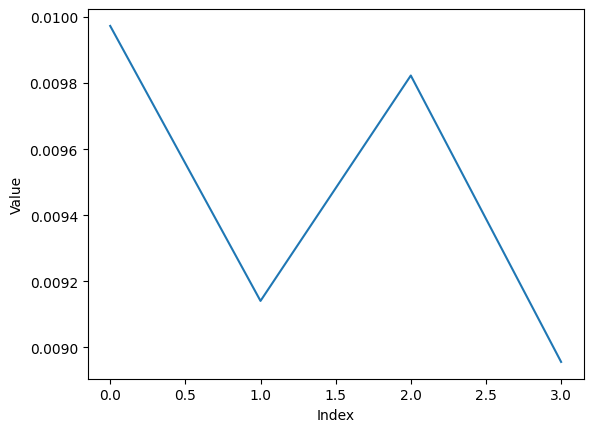

In [12]:
# RF
# starting point
if True:
    
    ne = RF["n_estimators"][0]
    md = RF["max_depth"][0]
    nb = RF["n_bins"][0]
    mf = RF["max_features"][0]
    
    while True:
        if ne > RF["n_estimators"][1]:
            ne = RF["n_estimators"][0]
            break
    
        while True:
            if md > RF["max_depth"][1]:
                md = RF["max_depth"][0]
                break
    
            while True:
                if nb > RF["n_bins"][1]:
                    nb = RF["n_bins"][0]
                    break
    
                while True:
                    if mf > RF["max_features"][1]:
                        mf = RF["max_features"][0]
                        break
    
                    model = RF["model"](n_estimators=ne, max_depth=md, n_bins=nb, max_features=mf)
                    model.fit(train_inputs, train_labels)
    
                    y_pred = model.predict(val_inputs)
    
                    mse = cuml.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = cp.sqrt(mse)
    
                    RF["results"].append(float(rmse))
    
                    del model
                    gc.collect()
    
                    mf = mf + RF["max_features"][2]
    
                nb = nb * RF["n_bins"][2]
    
            md = md + RF["max_depth"][2]
    
        ne = ne+ RF["n_estimators"][2]

    rel_test_loss = min(RF["results"])*100 / (val_labels.max()-val_labels.min())
    print(str(float(rel_test_loss)) + "%")

    plt.plot(range(len(RF["results"])), RF["results"])
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.show()

7.187360763549805%


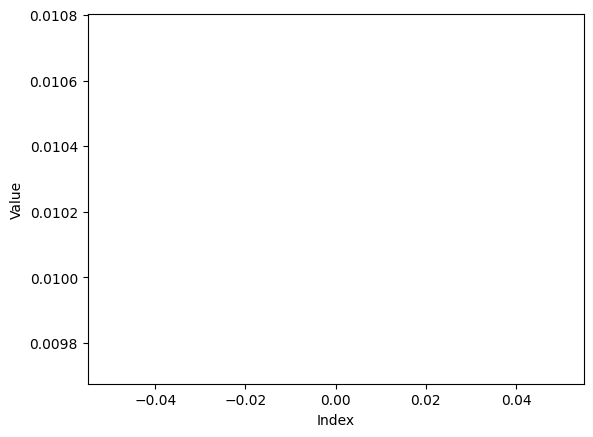

In [13]:
# ET
# starting point

if True:

    ne = ET["n_estimators"][0]
    md = ET["max_depth"][0]
    nb = ET["min_samples_leaf"][0]
    mf = ET["max_features"][0]
    
    while True:
        if ne > ET["n_estimators"][1]:
            ne = ET["n_estimators"][0]
            break
    
        while True:
            if md > ET["max_depth"][1]:
                md = ET["max_depth"][0]
                break
    
            while True:
                if nb > ET["min_samples_leaf"][1]:
                    nb = ET["min_samples_leaf"][0]
                    break
    
                while True:
                    if mf > ET["max_features"][1]:
                        mf = ET["max_features"][0]
                        break
    
                    model = ET["model"](n_estimators=ne, max_depth=md, min_samples_leaf=nb, max_features=mf)
                    model.fit(train_inputs, train_labels)
    
                    y_pred = model.predict(val_inputs)
    
                    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = np.sqrt(mse)
    
                    ET["results"].append(float(rmse))
    
                    mf = mf + ET["max_features"][2]
    
                nb = nb * ET["min_samples_leaf"][2]
    
            md = md + ET["max_depth"][2]
    
        ne = ne+ ET["n_estimators"][2]
    
        rel_test_loss = min(ET["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")
    
        plt.plot(range(len(ET["results"])), ET["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()

In [14]:
# make ET fast
from cuml import ForestInference

if True:
    
    y_pred = model.predict(val_inputs)
    
    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
    rmse = np.sqrt(mse)
    
    rel_test_loss = rmse*100 / (val_labels.max()-val_labels.min())
    print("unoptimized ET:" + str(float(rel_test_loss)) + "%")


    fil_model = ForestInference.load_from_sklearn(model)

    val_inputs_gpu = cp.asarray(val_inputs, dtype=cp.float32)
    y_pred_gpu = fil_model.predict(val_inputs_gpu)

    mse = cuml.metrics.mean_squared_error(val_labels, y_pred_gpu)
    rmse = cp.sqrt(mse)

    print("optimized ET:" + str(float(rel_test_loss)) + "%")

unoptimized ET:7.187360780567805%
optimized ET:7.187360780567805%


In [15]:
# XGB

X = {
    "model": xgb,
    "n_estimators": [500, 500, 50],
    "max_depth": [15, 15, 1],
    "min_child_weight": [3, 3, 1],
    "results": []
}

5.903713703155518%


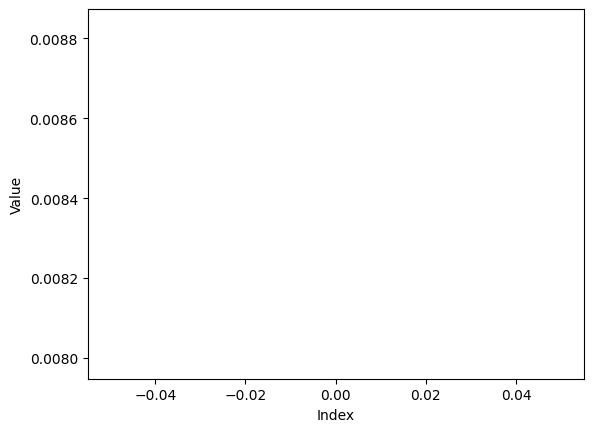

In [16]:
# XGB
# starting point

if True:

    ne = X["n_estimators"][0]
    md = X["max_depth"][0]
    mc = X["min_child_weight"][0]
    
    while True:
        if ne > X["n_estimators"][1]:
            ne = X["n_estimators"][0]
            break
    
        while True:
            if md > X["max_depth"][1]:
                md = X["max_depth"][0]
                break
    
            while True:
                if mc > X["min_child_weight"][1]:
                    mc = X["min_child_weight"][0]
                    break
    
                model = X["model"].XGBRegressor(n_estimators=ne, max_depth=md, min_child_weight=mc, learning_rate=0.05, tree_method="gpu_hist", gpu_id=0)
                model.fit(train_inputs, train_labels)

                y_pred = model.predict(val_inputs)

                mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                rmse = np.sqrt(mse)

                X["results"].append(float(rmse))
    
                mc = mc + X["min_child_weight"][2]
    
            md = md + X["max_depth"][2]
    
        ne = ne+ X["n_estimators"][2]
    
        rel_test_loss = min(X["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")
    
        plt.plot(range(len(X["results"])), X["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()

In [17]:
#### normal dataset ####

In [18]:
# RF

RF = {
    "model": RandomForestRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [20, 21, 1],
    "n_bins": [128, 256, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

In [19]:
# ET

ET = {
    "model": ExtraTreesRegressor,
    "n_estimators": [50, 50, 50],
    "max_depth": [21, 21, 1],
    "min_samples_leaf": [4, 4, 2],
    "max_features": [1.0, 1.0, 0.1],
    "results": []
}

In [20]:
datasetPath = Path("/home/philipm/Desktop/ML-For-CV-Robustness/datasets/datasetTrees.csv")

#making sure
datasetPath.is_file()

True

In [21]:
dataset = pd.read_csv(datasetPath)
dataset.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw,grviOut
0,0.176153,0.000341,0.000448,1141.969,1031.228,0.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0,0.088270
1,0.113641,0.000416,0.000502,1141.969,1031.228,1.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0,0.057202
2,0.095893,0.000464,0.000552,1141.969,1031.228,2.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0,0.048503
3,0.169083,0.000388,0.000506,1141.969,1031.228,3.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0,0.086477
4,0.137110,0.000399,0.000497,1141.969,1031.228,4.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0,0.067095


In [22]:
target_col = dataset["grviOut"]
labels = target_col.to_numpy(dtype="float32")
labels

array([0.08826979, 0.05720193, 0.04850335, ..., 0.09717431, 0.09026365,
       0.10635003], shape=(333760,), dtype=float32)

In [23]:
inputs = dataset.drop("grviOut", axis=1)
inputs.head()

,grviIn,meanRefR,meanRefG,illumR,illumG,blockIdx,sunRoll,sunPitch,sunYaw,camRoll,camPitch,camYaw
0,0.176153,0.000341,0.000448,1141.969,1031.228,0.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0
1,0.113641,0.000416,0.000502,1141.969,1031.228,1.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0
2,0.095893,0.000464,0.000552,1141.969,1031.228,2.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0
3,0.169083,0.000388,0.000506,1141.969,1031.228,3.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0
4,0.137110,0.000399,0.000497,1141.969,1031.228,4.0,180.0,-63.812729,-56.07412,0.0,-19.258,-0.0


In [24]:
inputs = inputs.to_numpy(dtype="float32")
inputs

array([[ 1.7615253e-01,  3.4053286e-04,  4.4844463e-04, ...,
         0.0000000e+00, -1.9257999e+01, -0.0000000e+00],
       [ 1.1364098e-01,  4.1558684e-04,  5.0227478e-04, ...,
         0.0000000e+00, -1.9257999e+01, -0.0000000e+00],
       [ 9.5892906e-02,  4.6407073e-04,  5.5236043e-04, ...,
         0.0000000e+00, -1.9257999e+01, -0.0000000e+00],
       ...,
       [ 2.8367174e-01,  2.6904649e-04,  4.2221454e-04, ...,
        -0.0000000e+00, -2.2218000e+01, -1.8000000e+02],
       [ 2.4132200e-01,  3.4478656e-04,  5.0772808e-04, ...,
        -0.0000000e+00, -2.2218000e+01, -1.8000000e+02],
       [ 2.7499148e-01,  3.2630350e-04,  5.1217148e-04, ...,
        -0.0000000e+00, -2.2218000e+01, -1.8000000e+02]],
      shape=(333760, 12), dtype=float32)

In [25]:
n_total = len(inputs)

n_train = int(0.8*n_total)
n_val = int(0.2*n_total)

# shuffle
g = torch.Generator().manual_seed(42)
perm = torch.randperm(n_total, generator=g).numpy()

inputs_shuf = inputs[perm]
labels_shuf = labels[perm]

# split
train_inputs, train_labels = inputs_shuf[:n_train], labels_shuf[:n_train]
val_inputs, val_labels = inputs_shuf[n_train:n_train + n_val], labels_shuf[n_train:n_train + n_val]

In [26]:
# keep only shaded parts

mask = val_inputs[:, 4] < 50

val_inputs = val_inputs[mask]
val_labels = val_labels[mask]

mask = train_inputs[:, 4] < 50

train_inputs = train_inputs[mask]
train_labels = train_labels[mask]

8.14121150970459%


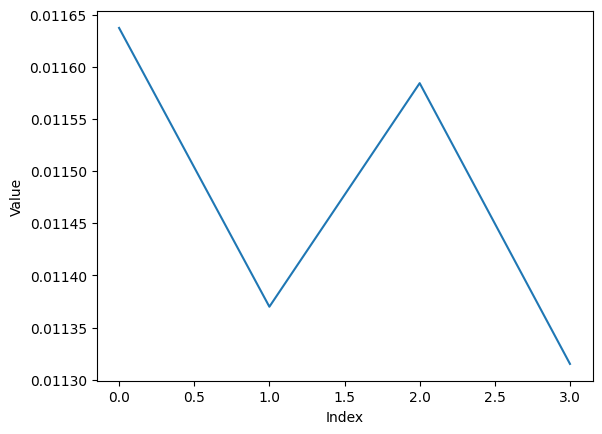

In [27]:
# RF
# starting point
if True:
    
    ne = RF["n_estimators"][0]
    md = RF["max_depth"][0]
    nb = RF["n_bins"][0]
    mf = RF["max_features"][0]
    
    while True:
        if ne > RF["n_estimators"][1]:
            ne = RF["n_estimators"][0]
            break
    
        while True:
            if md > RF["max_depth"][1]:
                md = RF["max_depth"][0]
                break
    
            while True:
                if nb > RF["n_bins"][1]:
                    nb = RF["n_bins"][0]
                    break
    
                while True:
                    if mf > RF["max_features"][1]:
                        mf = RF["max_features"][0]
                        break
    
                    model = RF["model"](n_estimators=ne, max_depth=md, n_bins=nb, max_features=mf)
                    model.fit(train_inputs, train_labels)
    
                    y_pred = model.predict(val_inputs)
    
                    mse = cuml.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = cp.sqrt(mse)
    
                    RF["results"].append(float(rmse))
    
                    del model
                    gc.collect()
    
                    mf = mf + RF["max_features"][2]
    
                nb = nb * RF["n_bins"][2]
    
            md = md + RF["max_depth"][2]
    
        ne = ne+ RF["n_estimators"][2]

    rel_test_loss = min(RF["results"])*100 / (val_labels.max()-val_labels.min())
    print(str(float(rel_test_loss)) + "%")

    plt.plot(range(len(RF["results"])), RF["results"])
    plt.xlabel("Index")
    plt.ylabel("Value")
    plt.show()

7.4121246337890625%


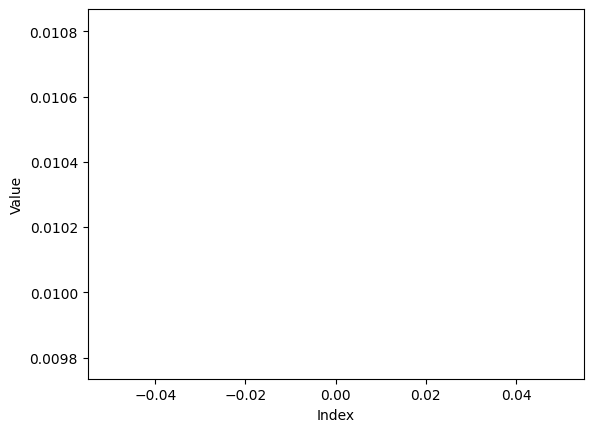

In [28]:
# ET
# starting point

if True:

    ne = ET["n_estimators"][0]
    md = ET["max_depth"][0]
    nb = ET["min_samples_leaf"][0]
    mf = ET["max_features"][0]
    
    while True:
        if ne > ET["n_estimators"][1]:
            ne = ET["n_estimators"][0]
            break
    
        while True:
            if md > ET["max_depth"][1]:
                md = ET["max_depth"][0]
                break
    
            while True:
                if nb > ET["min_samples_leaf"][1]:
                    nb = ET["min_samples_leaf"][0]
                    break
    
                while True:
                    if mf > ET["max_features"][1]:
                        mf = ET["max_features"][0]
                        break
    
                    model = ET["model"](n_estimators=ne, max_depth=md, min_samples_leaf=nb, max_features=mf)
                    model.fit(train_inputs, train_labels)
    
                    y_pred = model.predict(val_inputs)
    
                    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                    rmse = np.sqrt(mse)
    
                    ET["results"].append(float(rmse))
    
                    mf = mf + ET["max_features"][2]
    
                nb = nb * ET["min_samples_leaf"][2]
    
            md = md + ET["max_depth"][2]
    
        ne = ne+ ET["n_estimators"][2]
    
        rel_test_loss = min(ET["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")
    
        plt.plot(range(len(ET["results"])), ET["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()

In [29]:
# make ET fast
from cuml import ForestInference

if True:
    
    y_pred = model.predict(val_inputs)
    
    mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
    rmse = np.sqrt(mse)
    
    rel_test_loss = rmse*100 / (val_labels.max()-val_labels.min())
    print("unoptimized ET:" + str(float(rel_test_loss)) + "%")


    fil_model = ForestInference.load_from_sklearn(model)

    val_inputs_gpu = cp.asarray(val_inputs, dtype=cp.float32)
    y_pred_gpu = fil_model.predict(val_inputs_gpu)

    mse = cuml.metrics.mean_squared_error(val_labels, y_pred_gpu)
    rmse = cp.sqrt(mse)

    print("optimized ET:" + str(float(rel_test_loss)) + "%")

unoptimized ET:7.41212502459095%
optimized ET:7.41212502459095%


In [30]:
# XGB

X = {
    "model": xgb,
    "n_estimators": [500, 500, 50],
    "max_depth": [15, 15, 1],
    "min_child_weight": [3, 3, 1],
    "results": []
}

6.368427276611328%


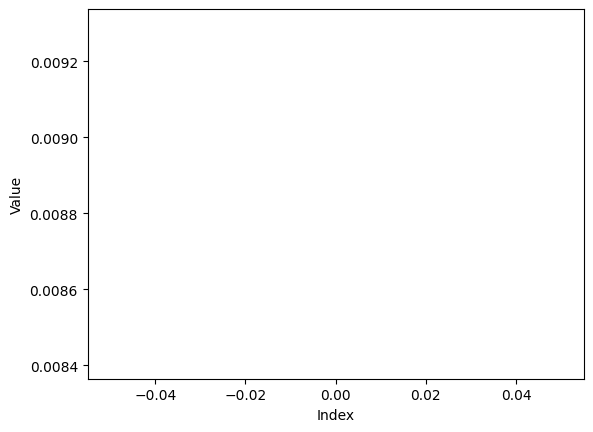

In [31]:
# XGB
# starting point

if True:

    ne = X["n_estimators"][0]
    md = X["max_depth"][0]
    mc = X["min_child_weight"][0]
    
    while True:
        if ne > X["n_estimators"][1]:
            ne = X["n_estimators"][0]
            break
    
        while True:
            if md > X["max_depth"][1]:
                md = X["max_depth"][0]
                break
    
            while True:
                if mc > X["min_child_weight"][1]:
                    mc = X["min_child_weight"][0]
                    break
    
                model = X["model"].XGBRegressor(n_estimators=ne, max_depth=md, min_child_weight=mc, learning_rate=0.05, tree_method="gpu_hist", gpu_id=0)
                model.fit(train_inputs, train_labels)

                y_pred = model.predict(val_inputs)

                mse = sklearn.metrics.mean_squared_error(val_labels, y_pred)
                rmse = np.sqrt(mse)

                X["results"].append(float(rmse))
    
                mc = mc + X["min_child_weight"][2]
    
            md = md + X["max_depth"][2]
    
        ne = ne+ X["n_estimators"][2]
    
        rel_test_loss = min(X["results"])*100 / (val_labels.max()-val_labels.min())
        print(str(float(rel_test_loss)) + "%")
    
        plt.plot(range(len(X["results"])), X["results"])
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.show()